### DATA PREPROCESSING

Read data serta memeriksa apakah ada missing values. Jika ada, ditambahkan dengan median (numerikal) ataupun modus (kategorikal).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras import models, layers
import pyarrow.parquet as pq

table = pq.read_table("2B.parquet")
df = table.to_pandas()

print(df.head())
print("\nMissing values:\n", df.isna().sum())
print("\nData types:\n", df.dtypes)


for col in df.columns:
    if df[col].isna().sum() > 0:
        if df[col].dtype != "object":
            df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

   Sales_ID       name  year  selling_price   Region State or Province  \
0      4333     Maruti  2018         6000.0  Central          Nebraska   
1      5562       Tata  2012         1400.0  Central          Illinois   
2      6854  Chevrolet  2015         4340.0     East          New York   
3      8113       Ford  2018         7460.0    South    North Carolina   
4      6986       Tata  2017         3700.0     East          Maryland   

            City    fuel seller_type transmission               owner mileage  \
0        Norfolk  Petrol      Dealer    Automatic         First_Owner    22.0   
1    Bloomington  Diesel  Individual       Manual  Fourth_Above_Owner   19.09   
2    Schenectady  Diesel  Individual       Manual         First_Owner   13.58   
3    Mooresville  Diesel  Individual       Manual         First_Owner    24.4   
4  Silver Spring  Petrol  Individual       Manual         First_Owner   17.57   

   engine  max_power               torque  seats  
0    1197      81

Menentukan target column dan juga variabel column

Untuk torque dengan dua value yang berbeda dalam satu kolom, dipisah menjadi dua kolom berbeda. Dilakukan juga train test split agar nantinya bisa digunakan pada learning model

In [3]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

TARGET_COLUMN = 'selling_price'

X = df.drop(columns=[TARGET_COLUMN, 'Sales_ID'])
y = df[TARGET_COLUMN]

import re

def clean_torque(value):
    torque_match = re.search(r'(\d+)\s*Nm', value)
    rpm_match = re.search(r'@\s*(\d+)\s*rpm', value)

    torque_nm = int(torque_match.group(1)) if torque_match else None
    torque_rpm = int(rpm_match.group(1)) if rpm_match else None

    return torque_nm, torque_rpm

df['torque_nm'], df['torque_rpm'] = zip(*df['torque'].apply(clean_torque))

df = df.drop(columns=['torque'])

df['torque_nm'] = df['torque_nm'].fillna(df['torque_nm'].median())
df['torque_rpm'] = df['torque_rpm'].fillna(df['torque_rpm'].median())

categorical_cols = X.select_dtypes(include=['object']).columns
print("Categorical Columns:", categorical_cols)

for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=10)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=10)

print(X.dtypes)

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(X_train) 
y_train = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).flatten()

X_val = scaler_X.transform(X_val)  
y_val = scaler_y.transform(y_val.values.reshape(-1, 1)).flatten()  

X_test = scaler_X.transform(X_test)  
y_test = scaler_y.transform(y_test.values.reshape(-1, 1)).flatten()  

Categorical Columns: Index(['name', 'Region', 'State or Province', 'City', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage', 'torque'],
      dtype='object')
name                   int64
year                   int64
Region                 int64
State or Province      int64
City                   int64
fuel                   int64
seller_type            int64
transmission           int64
owner                  int64
mileage                int64
engine                 int64
max_power            float64
torque                 int64
seats                  int64
dtype: object


In [4]:
df.columns
print(df.isna().sum())

df.describe()
df.to_csv('cleaned_data2.xlsx', index=False)

print("Columns in X:", X.shape[1])
print("ANN expects:", X_train.shape[1])

print("Any NaN values in X_train?", pd.DataFrame(X_train).isna().any().any())
print("Any infinite values in X_train?", (pd.DataFrame(X_train) == float('inf')).any().any())

Sales_ID             0
name                 0
year                 0
selling_price        0
Region               0
State or Province    0
City                 0
fuel                 0
seller_type          0
transmission         0
owner                0
mileage              0
engine               0
max_power            0
seats                0
torque_nm            0
torque_rpm           0
dtype: int64
Columns in X: 14
ANN expects: 14
Any NaN values in X_train? False
Any infinite values in X_train? False


### SIGMOID

Dalam kode ini, sebuah model neural network dibuat menggunakan Keras dengan empat lapisan Dense, masing-masing dengan 512, 256, dan 128 neuron yang menggunakan aktivasi sigmoid, dan satu lapisan output untuk memprediksi harga jual mobil. Model ini dikompilasi dengan optimizer Adam dan fungsi loss "mean_squared_error" untuk regresi, serta menggunakan metrik "mae" (Mean Absolute Error)

Epoch 1/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.2073 - mae: 0.5874 - val_loss: 0.4282 - val_mae: 0.3357
Epoch 2/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2546 - mae: 0.2625 - val_loss: 0.1774 - val_mae: 0.2376
Epoch 3/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1924 - mae: 0.2440 - val_loss: 0.1805 - val_mae: 0.2120
Epoch 4/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1621 - mae: 0.2212 - val_loss: 0.1509 - val_mae: 0.2305
Epoch 5/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1854 - mae: 0.2421 - val_loss: 0.1282 - val_mae: 0.1896
Epoch 6/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1166 - mae: 0.1990 - val_loss: 0.0906 - val_mae: 0.1737
Epoch 7/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1527 - mae: 0.2301 - val_loss: 0.1029 - val_mae: 0.1922
Epoch 8/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1021 - mae: 0.1890 - val_loss: 0.1071 - val_mae: 0.1711
Epoch 9/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1534 - mae: 

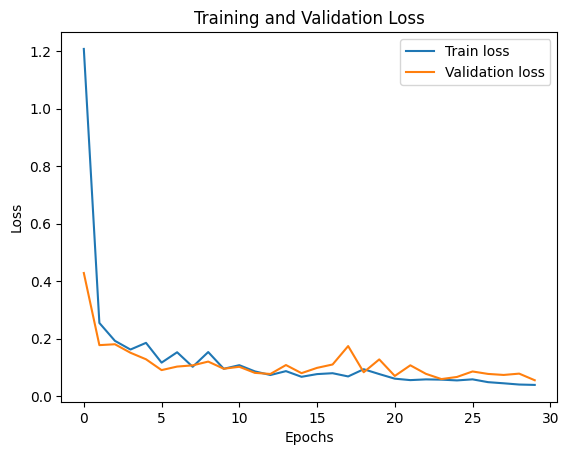

In [5]:
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import r2_score

model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),  
    layers.Dense(512, activation="sigmoid"),  
    layers.Dense(256, activation="sigmoid"),  
    layers.Dense(128, activation="sigmoid"),  
    layers.Dense(1)  
])

optimizer = Adam(learning_rate=0.01)

model.compile(optimizer=optimizer, loss="mean_squared_error", metrics=["mae"])

history = model.fit(X_train, y_train, epochs=30, validation_data=(X_val, y_val))

test_loss, test_mae = model.evaluate(X_test, y_test)
print(f"\nTest Loss: {test_loss}")
print(f"Test MAE: {test_mae}")

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f"R-squared: {r2}")

import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()


Hasil dari pelatihan model menunjukkan progres yang cukup baik dalam memprediksi harga jual mobil. Selama 30 epoch, loss dan MAE (Mean Absolute Error) pada data pelatihan cenderung menurun, sementara pada data validasi terlihat fluktuasi tetapi tetap menunjukkan tren penurunan, yang mengindikasikan bahwa model belajar dengan baik

### MODIFIED MODEL

Adanya dropout rate yang ditambahkan, early stopping dan juga reduce learning rate ketika val_loss tidak bertambah atau stagnan.

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4687 - mae: 0.4687 - val_loss: 0.3516 - val_mae: 0.3516 - learning_rate: 1.0000e-04
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3830 - mae: 0.3830 - val_loss: 0.3120 - val_mae: 0.3120 - learning_rate: 1.0000e-04
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3473 - mae: 0.3473 - val_loss: 0.2865 - val_mae: 0.2865 - learning_rate: 1.0000e-04
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3209 - mae: 0.3209 - val_loss: 0.2588 - val_mae: 0.2588 - learning_rate: 1.0000e-04
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2976 - mae: 0.2976 - val_loss: 0.2411 - val_mae: 0.2411 - learning_rate: 1.0000e-04
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2840 - mae: 0.2840 - val_loss: 0.2324 - val_mae: 0.2324 - learning_rate: 1.0000e-04
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2843 - mae: 0.2843 - val_loss: 0.2267 - val_mae: 0.2267 - learning_ra

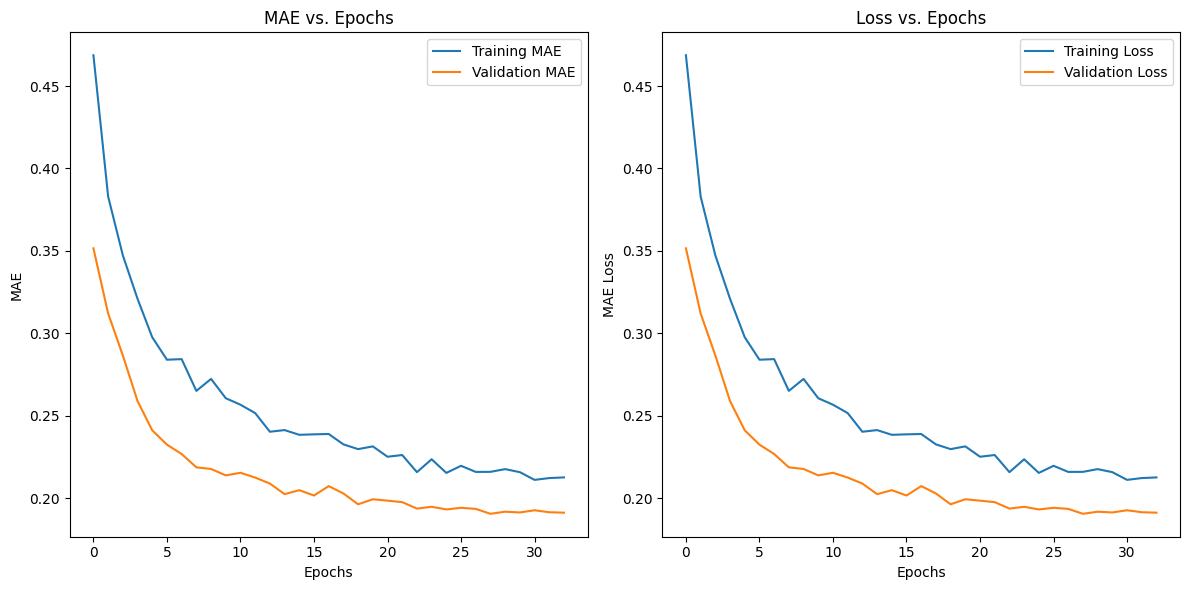

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1973 - mae: 0.1973 
Test Loss: 0.19729752838611603
Test MAE: 0.19729752838611603


In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

model_mod = Sequential([
    tf.keras.Input(shape=(X_train_scaled.shape[1],)),
    Dense(256, activation='relu'),
    Dropout(0.2),  
    Dense(128, activation='relu'),
    Dropout(0.2),  
    Dense(64, activation='relu'),
    Dropout(0.2),  
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])

optimizer = Adam(learning_rate=0.0001)  
model_mod.compile(
    optimizer=optimizer,
    loss='mae',
    metrics=['mae']
)

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=0.00001)

history = model_mod.fit(
    X_train_scaled,
    y_train,
    epochs=100, 
    batch_size=32,
    validation_data=(X_val_scaled, y_val),
    verbose=1,
    callbacks=[early_stopping, reduce_lr]
)

history_dict = history.history

plt.figure(figsize=(12, 6))

# MAE Plot
plt.subplot(1, 2, 1)
plt.plot(history_dict['mae'], label='Training MAE')
plt.plot(history_dict['val_mae'], label='Validation MAE')
plt.title('MAE vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history_dict['loss'], label='Training Loss')
plt.plot(history_dict['val_loss'], label='Validation Loss')
plt.title('Loss vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('MAE Loss')
plt.legend()

plt.tight_layout()
plt.show()

test_loss, test_mae = model_mod.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss}")
print(f"Test MAE: {test_mae}")


### EVALUATION

Model without modification terlihat lebih unggul dikarenakan menunjukkan R-squared yang jauh lebih tinggi (92%), yang menandakan bahwa model lebih akurat dalam memprediksi harga jual dibandingkan setelah modifikasi

In [8]:
from sklearn.metrics import r2_score
import numpy as np

before_loss, before_mae = model.evaluate(X_test, y_test, verbose=1)
before_predictions = model.predict(X_test)
before_r2 = r2_score(y_test, before_predictions)

print("\n=== BEFORE MODEL ===")
print(f"Test Loss: {before_loss}")
print(f"Test MAE: {before_mae}")
print(f"R² Score: {before_r2}")


after_loss, after_mae = model_mod.evaluate(X_test, y_test, verbose=1)
after_predictions = model_mod.predict(X_test)
after_r2 = r2_score(y_test, after_predictions)

print("\n=== AFTER MODEL ===")
print(f"Test Loss: {after_loss}")
print(f"Test MAE: {after_mae}")
print(f"R² Score: {after_r2}")


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0646 - mae: 0.1644 
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 

=== BEFORE MODEL ===
Test Loss: 0.06458646059036255
Test MAE: 0.16442936658859253
R² Score: 0.9276579196487753
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1973 - mae: 0.1973 
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

=== AFTER MODEL ===
Test Loss: 0.19729752838611603
Test MAE: 0.19729752838611603
R² Score: 0.8351509435918831
